# Прогнозирование продаж: анализ и предобработка временного ряда

Анализируем продажи товара `84692` (*BOX OF 24 COCKTAIL PARASOLS*, набор из 24 коктейльных зонтиков) по данным Online Retail (UCI) с 01.12.2010 по 09.12.2011 

Считаем, сколько единиц товара (`Quantity`) продано за каждый период.

Код анализа собран в [`ts_tools.py`](ts_tools.py). В ноутбуке вызываем функции и разбираем результаты.

In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf

import ts_tools as T

pd.set_option("display.precision", 3)
CODE = "84692"
DATA = Path("../Online Retail.xlsx")

## Шаг 1. Данные и формирование временного ряда
### 1.1 Структура данных

In [26]:
df = T.load_transactions(DATA)
print(df.shape)
df.info()
fields = ["StockCode", "InvoiceDate", "Quantity", "InvoiceNo", "UnitPrice"]
print("Пропуски в полях для построения ряда:")
display(df[fields].isna().sum().rename("пропусков"))
df.head()

StockCode      0
InvoiceDate    0
Quantity       0
InvoiceNo      0
UnitPrice      0
Name: пропусков, dtype: int64

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,date,code
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01,85123A
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,71053
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01,84406B
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,84029G
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,84029E


Поля для построения ряда

| Поле | Зачем |
|---|---|
| `StockCode` | отбор товара (в столбце смешаны числа и строки, поэтому приводим к `str`) |
| `InvoiceDate` | дата продажи (берём календарный день) |
| `Quantity` | показатель продаж — число проданных единиц |
| `InvoiceNo` | счета с префиксом `C` — возвраты, их исключаем |
| `UnitPrice` | строки с нулевой ценой — служебные корректировки, не продажи |

### 1.2 Выбранный товар

In [27]:
raw = df[df.code == CODE]
print("Название:", raw.Description.unique())
print("Строк в транзакциях:", len(raw), "| дней с продажами:", T.product_sales(df, CODE).date.nunique())
print("\nСтроки, которые НЕ являются продажами (возвраты и нулевая цена):")
raw.loc[raw.index.difference(T.product_sales(df, CODE).index)][["InvoiceNo", "Quantity", "UnitPrice", "InvoiceDate"]]

,InvoiceNo,Quantity,UnitPrice,InvoiceDate
14337,537534,2,0.00,2010-12-07 11:48:00
41453,539856,2,0.00,2010-12-22 14:41:00
53364,540832,1,0.00,2011-01-11 14:42:00
104427,545176,1,0.00,2011-02-28 14:19:00
235928,C557663,-25,0.42,2011-06-21 17:59:00
242410,558340,1,0.00,2011-06-28 14:01:00
263927,C560045,-1,0.42,2011-07-14 14:51:00
264500,C560099,-5,0.42,2011-07-14 17:47:00


Из 603 строк по товару исключаем 8. Это 3 возврата и 5 строк с нулевой ценой. В объём продаж включаем только положительные количества по положительной цене (`T.product_sales`).

### 1.3 Календарь магазина

In [28]:
names = {0: "Пн", 1: "Вт", 2: "Ср", 3: "Чт", 4: "Пт", 5: "Сб", 6: "Вс"}
open_days = T.trading_days(df)
cnt = pd.Series(open_days.dayofweek).map(names).value_counts().reindex(list(names.values())).fillna(0).astype(int)
print("Торговых дней по дням недели:\n", cnt.to_string())
cal = pd.date_range(df.date.min(), df.date.max())
closed = cal.difference(open_days)
print("\nКалендарных дней:", len(cal), "| без единой транзакции:", len(closed), "| из них суббот:", (closed.dayofweek == 5).sum())
print("Дни без транзакций, кроме суббот:", [d.strftime("%d.%m.%Y") for d in closed[closed.dayofweek != 5]])

В выгрузке нет транзакций по субботам, поэтому в дневном ряду оставляем шесть позиций в неделю (Пн–Пт и Вс). Ещё в 16 дат, помимо суббот, в выгрузке нет транзакций по всему магазину.

* Когда в магазине есть транзакции, а у товара после фильтрации продаж нет, записываем **0 проданных единиц**.
* Когда по магазину нет транзакций, ставим **NaN**. Часть пропусков, вероятно, связана с праздничными закрытиями. Выгрузка не позволяет установить причину для каждой даты.

In [29]:
daily = T.make_daily(df, CODE)
weekly = T.aggregate(daily, "W")
monthly = T.aggregate(daily, "M")

agg = pd.DataFrame({
    "позиций": [len(daily), len(weekly), len(monthly)],
    "начало": [daily.index[0].date(), weekly.index[0].date(), monthly.index[0].date()],
    "конец": [daily.index[-1].date(), weekly.index[-1].date(), monthly.index[-1].date()],
    "всего продано": [daily.sum(), weekly.sum(), monthly.sum()],
    "среднее за период": [daily.mean(), weekly.mean(), monthly.mean()],
}, index=["день (Пн–Пт, Вс)", "неделя (Пн–Вс)", "месяц"])
agg

,позиций,начало,конец,всего продано,среднее за период
"день (Пн–Пт, Вс)",321,2010-12-01,2011-12-09,7908.0,25.928
неделя (Пн–Вс),52,2010-12-12,2011-12-04,7548.0,148.000
месяц,12,2010-12-01,2011-11-01,7689.0,640.750


Из недельного ряда исключаем первую (01–05.12.2010) и последнюю (05–09.12.2011) неполные недели. Из месячного исключаем декабрь 2011 года, за который есть данные только за первые 9 дней. В коротких периодах сумма была бы ниже из-за их длины. Дневной ряд включает эти даты, поэтому его общая сумма выше недельной и месячной.

За каждый период суммируем только наблюдаемые продажи. Если наблюдений нет за весь период, оставляем NaN.

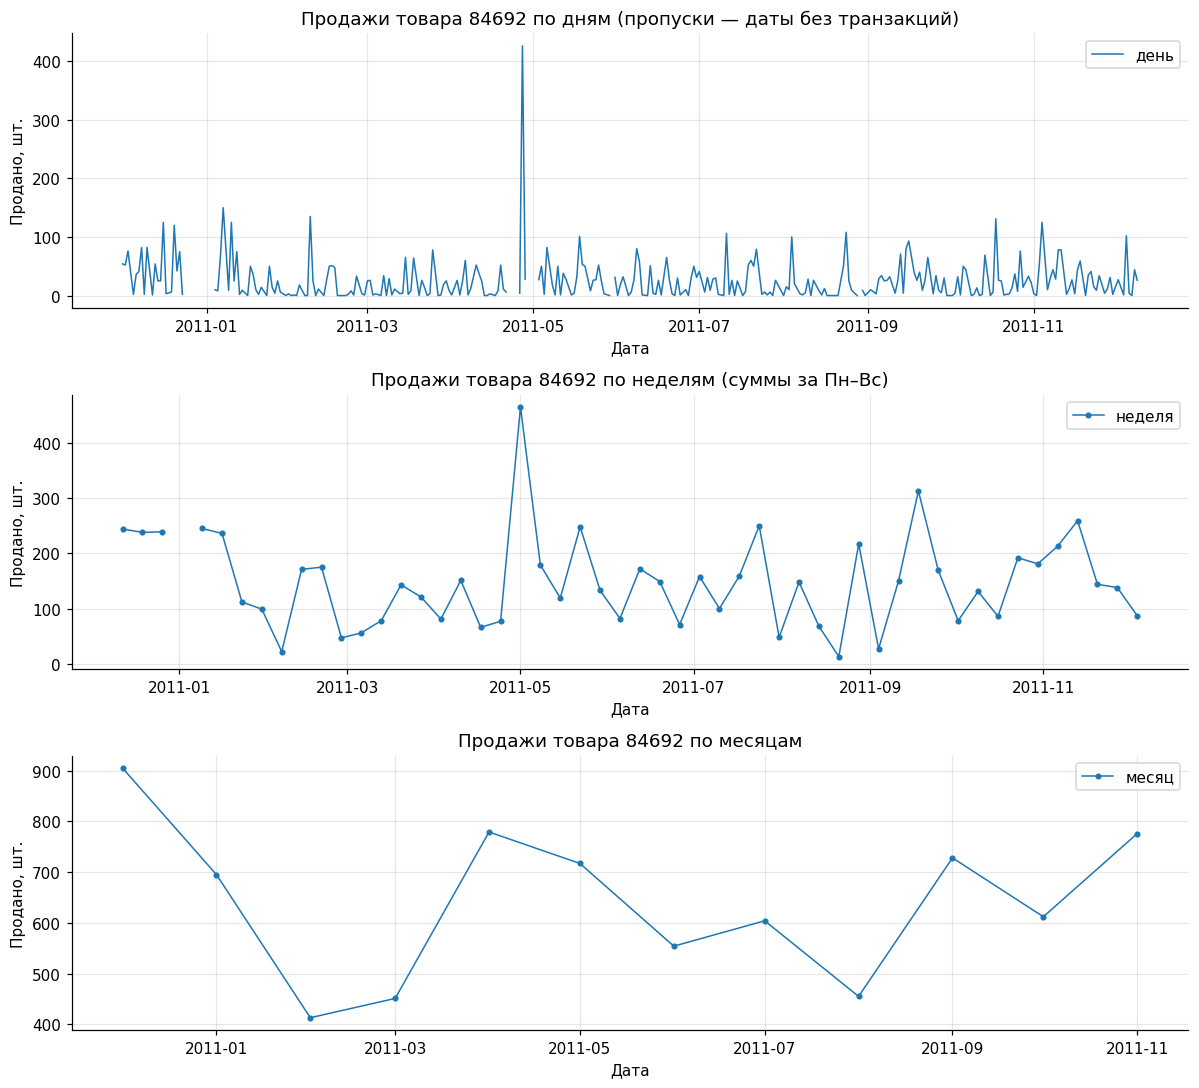

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10))
T.plot_series(daily, "Продажи товара 84692 по дням (пропуски — даты без транзакций)", ax=axes[0], label="день")
T.plot_series(weekly, "Продажи товара 84692 по неделям (суммы за Пн–Вс)", ax=axes[1], label="неделя")
T.plot_series(monthly, "Продажи товара 84692 по месяцам", ax=axes[2], label="месяц")
fig.tight_layout()

## Шаг 2. Качество данных
### 2.1 Пропуски

,start,end,n_days
0,2010-12-24,2011-01-03,9
1,2011-04-22,2011-04-25,3
2,2011-04-29,2011-04-29,1
3,2011-05-02,2011-05-02,1
4,2011-05-30,2011-05-30,1
5,2011-08-29,2011-08-29,1


<Axes: title={'center': 'Дневной ряд до обработки: дни без транзакций отмечены оранжевым'}, xlabel='Дата', ylabel='Продано, шт.'>

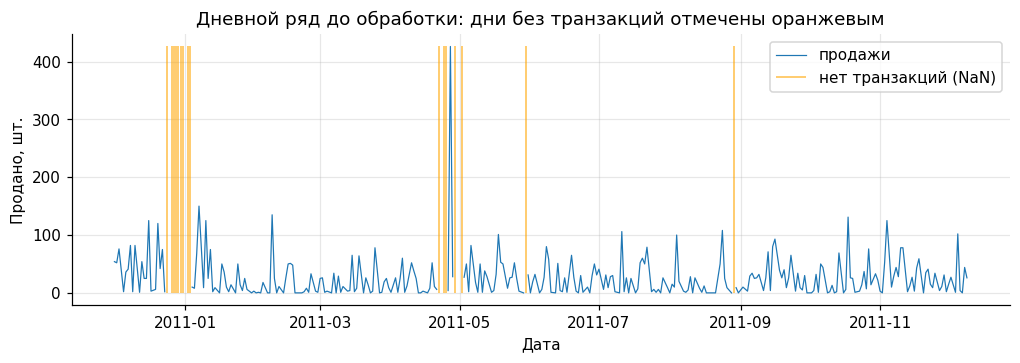

In [31]:
miss = T.missing_report(daily)
print("Дней без транзакций (NaN) в дневном ряду:", int(daily.isna().sum()), "из", len(daily))
display(miss)
cd = T.closed_days_per_period(daily, "W")
print("Недель, в которых была хотя бы одна дата с NaN:", int((cd.reindex(weekly.index) > 0).sum()), "из", len(weekly))
print("Недели без единой транзакции, дата конца недели:", [str(d.date()) for d in weekly[weekly.isna()].index])
print("Дней с транзакциями магазина, но без продаж товара:", int((daily == 0).sum()),
      f"({(daily.dropna() == 0).mean():.1%} торговых дней)")
T.plot_missing(daily, "Дневной ряд до обработки: дни без транзакций отмечены оранжевым")

Во всех полях, по которым строим ряд, значения заполнены. После построения календаря в дневном ряду появилось 16 дат с NaN. Хотя бы один такой день есть в 8 из 52 полных недель.

Самый длинный отрезок без транзакций приходится на 24.12.2010–03.01.2011. В нём девять дней без учёта суббот. На неделе 27.12.2010–02.01.2011 транзакций нет вовсе, поэтому её итог остаётся NaN.

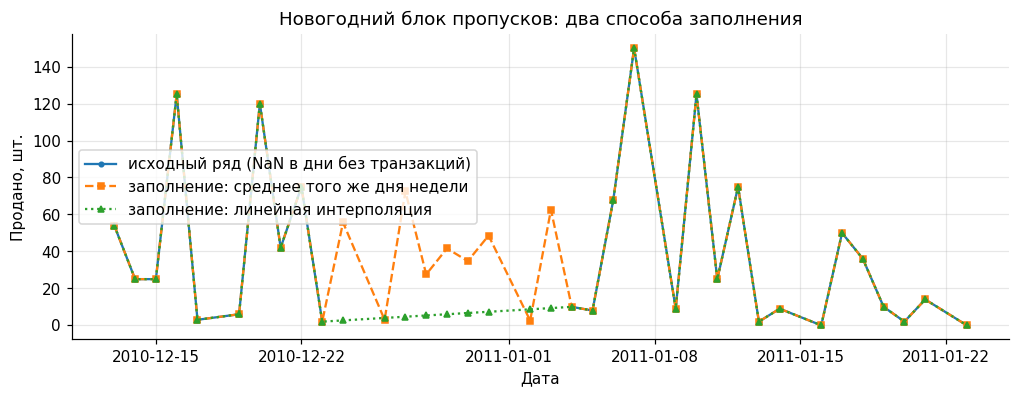

In [32]:
filled = T.impute_closed_days(daily, "weekday")
linear = T.impute_closed_days(daily, "linear")
weekly_filled = T.impute_closed_days(weekly, "linear")
w = slice("2010-12-13", "2011-01-23")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily[w].index, daily[w], "o-", c="C0", ms=3, label="исходный ряд (NaN в дни без транзакций)")
ax.plot(filled[w].index, filled[w], "s--", c="C1", ms=4, label="заполнение: среднее того же дня недели")
ax.plot(linear[w].index, linear[w], "^:", c="C2", ms=4, label="заполнение: линейная интерполяция")
ax.set(title="Новогодний блок пропусков: два способа заполнения", xlabel="Дата", ylabel="Продано, шт."); ax.legend()
print("Среднее до/после заполнения:", round(daily.mean(), 2), "/", round(filled.mean(), 2),
      "| СКО:", round(daily.std(), 2), "/", round(filled.std(), 2))

Дневные пропуски заполняем средним по тому же дню недели, чтобы сохранить разницу между буднями и воскресеньем. После заполнения среднее меняется с 25,93 до 26,14 шт., а СКО с 37,29 до 36,65 шт.

Пропущенную неделю заполняем линейной интерполяцией между соседними неделями для расчёта ACF, спектра и тестов стационарности. Заполненные значения используем только в ретроспективных расчётах на полной сетке. Недельные и месячные суммы, диагностику выбросов и статистику фактических продаж рассчитываем до заполнения.

In [33]:
rows = []
for name, s in [("день", daily), ("неделя", weekly), ("месяц", monthly)]:
    rows.append({"ряд": name, **{m: len(T.detect_outliers(s, m)) for m in ["iqr", "mad", "zscore"]}})
display(pd.DataFrame(rows).set_index("ряд"))
out_d = T.detect_outliers(daily, "iqr")
print("Топ-8 выбросов дневного ряда (IQR):"); display(out_d.head(8))
print("Выбросы недельного ряда (IQR):"); display(T.detect_outliers(weekly, "iqr"))

,iqr,mad,zscore
ряд,,,
день,14,17,2
неделя,1,0,1
месяц,0,0,0


,value,score
2011-04-27,426.0,12.906
2011-01-07,150.0,4.281
2011-02-08,135.0,3.812
2011-10-18,131.0,3.688
2010-12-16,125.0,3.500
2011-01-10,125.0,3.500
2011-11-04,125.0,3.500
2010-12-20,120.0,3.344


,value,score
2011-05-01,465.0,3.057


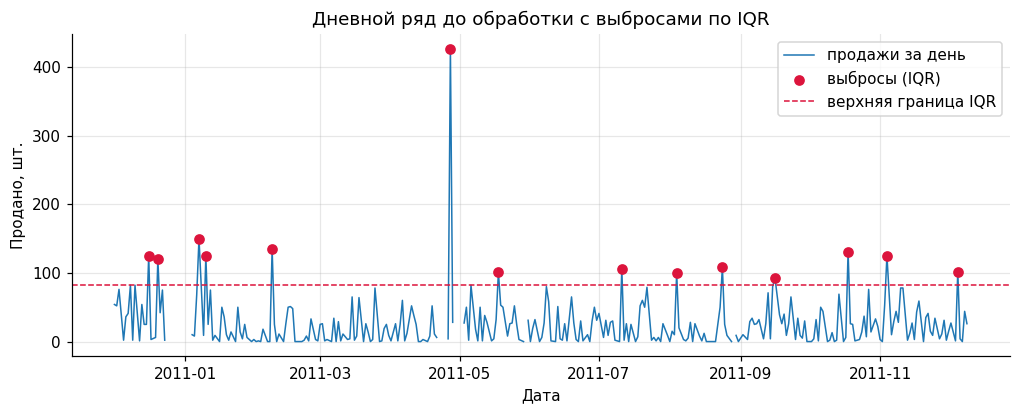

In [34]:
fig, ax = plt.subplots(figsize=(11, 3.8))
T.plot_series(daily, "Дневной ряд до обработки с выбросами по IQR", ax=ax, mark=out_d["value"], label="продажи за день")
q1, q3 = daily.quantile([.25, .75]); ax.axhline(q3 + 1.5 * (q3 - q1), c="crimson", ls="--", lw=1, label="верхняя граница IQR")
ax.legend()

IQR отмечает много дней, поскольку распределение сильно скошено вправо. Мелких заказов много, оптовые редки. По величине выделяется один день, 27.04.2011. В тот день продано **426 шт.**, на 12,9 межквартильного размаха выше медианы. Следующие значения (150, 135, 131 и 125) относятся к обычному хвосту оптовых заказов.

IQR отмечает только одну неделю, 25.04–01.05.2011. MAD не выявляет выбросов ни в недельном, ни в месячном ряду.

In [35]:
p = T.product_sales(df, CODE)
day = p[p.date == "2011-04-27"][["InvoiceNo", "Quantity", "UnitPrice", "CustomerID", "Country"]]
display(day)
share = day.Quantity.max() / weekly["2011-05-01"]
print(f"Доля одного заказа в продажах недели 25.04–01.05.2011: {share:.0%}")
print("Заказов товара с Quantity >= 100 за весь период:", int((p.Quantity >= 100).sum()),
      "| медиана размера заказа:", p.Quantity.median())

,InvoiceNo,Quantity,UnitPrice,CustomerID,Country
169623,551194,1,0.42,14606.0,United Kingdom
169977,551271,25,0.42,17187.0,United Kingdom
170369,551291,400,0.32,14298.0,United Kingdom


**Дневное значение сохраняем без корректировки.** Его объясняет реальный оптовый заказ на 400 шт. по 0,32 за штуку вместо 0,42 (счёт 551291). В выгрузке есть оптовые клиенты, и заказы по 100 штук встречаются регулярно. Удаление этого дневного значения исказило бы наблюдаемый объём продаж. Такие всплески тоже нужно учитывать при прогнозировании.

В шаге 5 повторяем тесты стационарности с ограничением верхнего 1% значений (winsorize), чтобы проверить, меняется ли вывод.

## Шаг 3. Визуальный и описательный анализ
### 3.1 Описательные статистики и дополнительные характеристики
Дневные статистики считаем по датам, когда в выгрузке есть транзакции магазина.

In [36]:
desc = pd.DataFrame({"день": T.describe_series(daily), "неделя": T.describe_series(weekly),
                     "месяц": T.describe_series(monthly)})
desc

,день,неделя,месяц
n,305.000,5.100e+01,1.200e+01
mean,25.928,1.480e+02,6.408e+02
median,13.000,1.440e+02,6.535e+02
std,37.291,8.421e+01,1.525e+02
cv,1.438,5.690e-01,2.379e-01
min,0.000,1.300e+01,4.130e+02
max,426.000,4.650e+02,9.050e+02
range,426.000,4.520e+02,4.920e+02
q1,2.000,8.150e+01,5.292e+02
q3,34.000,1.865e+02,7.400e+02


* **Дневной ряд.** Среднее заметно выше медианы, а коэффициент вариации CV больше 1. Большая положительная асимметрия и высокий эксцесс указывают на тяжёлый правый хвост. Из-за оптовых заказов пик-фактор составляет около 9. Дневной максимум примерно в девять раз выше среднеквадратического уровня. Около 15% наблюдаемых дней дают ноль продаж.
* **Недельный ряд.** CV падает примерно до 0,6, а асимметрия уменьшается при агрегации. Недельные суммы сглаживают дневные колебания. Неделя без транзакций в конце декабря 2010 года в расчёт статистик не входит.
* **Месячный ряд.** Статистики по 12 точкам дают общее представление о ряде.
* **Показатель Херста** (R/S) около 0,66–0,76 формально указывает на персистентность. Оценка по наблюдаемым значениям чувствительна к длине выборки, выбросам и календарным эффектам, поэтому её недостаточно для вывода о длинной памяти.

### 3.2 Изменение уровня и разброса во времени

,среднее,СКО
1-я половина (дек 2010 – июнь 2011),153.080,95.828
2-я половина (июнь – дек 2011),143.115,72.925


,2010-12-01,2011-01-01,2011-02-01,2011-03-01,2011-04-01,2011-05-01,2011-06-01,2011-07-01,2011-08-01,2011-09-01,2011-10-01,2011-11-01
шт.,905.0,695.0,413.0,451.0,779.0,717.0,554.0,604.0,455.0,728.0,612.0,776.0


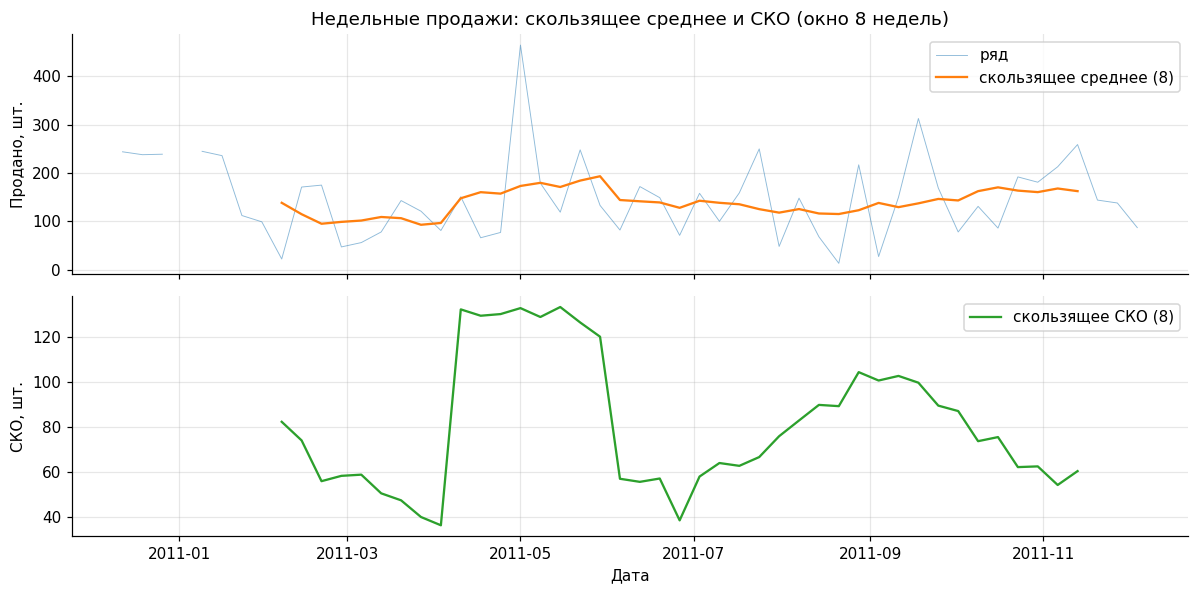

In [37]:
T.plot_rolling(weekly, 8, "Недельные продажи: скользящее среднее и СКО (окно 8 недель)")
half = len(weekly) // 2
cmp = pd.DataFrame({"среднее": [weekly.iloc[:half].mean(), weekly.iloc[half:].mean()],
                    "СКО": [weekly.iloc[:half].std(), weekly.iloc[half:].std()]},
                   index=["1-я половина (дек 2010 – июнь 2011)", "2-я половина (июнь – дек 2011)"])
display(cmp)
print("Тренд, недельный ряд:", {k: round(float(v), 4) for k, v in T.trend_test(weekly).items()})
print("Тренд, месячный ряд: ", {k: round(float(v), 4) for k, v in T.trend_test(monthly).items()})
print("\nПродажи по месяцам:"); monthly.rename("шт.").to_frame().T

Наклон линейной регрессии и корреляция Спирмена со временем статистически незначимы на недельной и месячной частотах. Устойчивого тренда за этот период не видно.

В первой половине периода продавалось в среднем 153 шт. в неделю, во второй 143 шт. Разброс выше в первой половине (СКО около 96 и 73 шт. соответственно). На первую половину пришёлся апрельский заказ на 400 шт. Среди полных месяцев больше всего продали в декабре 2010 года (905 шт.), меньше всего в феврале (413 шт.). Скользящее СКО меняется со временем.

### 3.3 Недельная закономерность

,mean,median,n
Пн,25.979,22.0,47
Вт,29.077,26.0,52
Ср,32.528,11.0,53
Чт,27.038,25.0,53
Пт,33.540,25.5,50
Вс,6.820,2.0,50


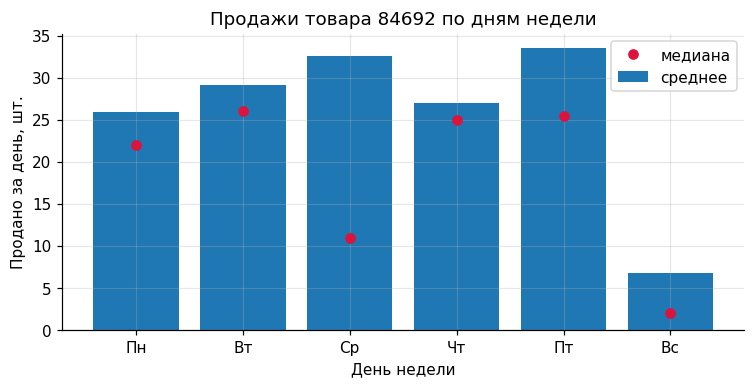

In [38]:
prof = T.weekday_profile(daily)
display(prof)
h, pval = T.kruskal_by_weekday(daily)
print(f"Критерий Краскела–Уоллиса по дням недели: H = {h:.1f}, p = {pval:.2e}")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(prof.index, prof["mean"], color="C0", label="среднее"); ax.plot(prof.index, prof["median"], "o", c="crimson", label="медиана")
ax.set(title="Продажи товара 84692 по дням недели", xlabel="День недели", ylabel="Продано за день, шт."); ax.legend()

По воскресеньям продавалось в среднем около 7 шт., по будням от 26 до 34. Медиана в воскресенье равна 2 шт., в будни она лежит между 11 и 26 шт. Тест Краскела–Уоллиса показывает статистически значимое различие между группами в целом (p ≈ 8·10⁻⁸). Низкие продажи по воскресеньям оказались главной регулярной закономерностью ряда.

### 3.4 Автокорреляция и спектр

,lb_stat,lb_pvalue
6,3.398,0.757
12,5.279,0.948
24,31.157,0.149


,lb_stat,lb_pvalue
4,6.426,0.169
8,7.855,0.448
13,16.190,0.239


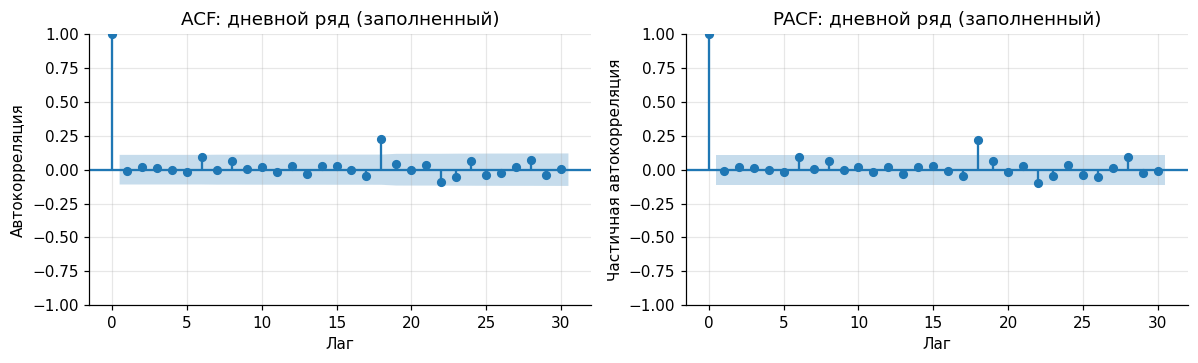

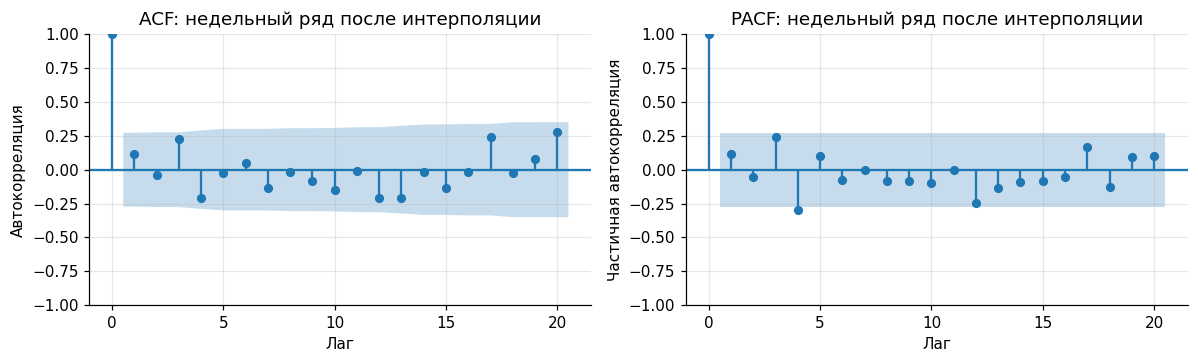

In [39]:
T.plot_acf_pacf(filled, 30, "дневной ряд (заполненный)")
T.plot_acf_pacf(weekly_filled, 20, "недельный ряд после интерполяции")
print("Тест Льюнга–Бокса (H0: автокорреляции нет), дневной ряд:"); display(T.ljung_box(filled, [6, 12, 24]))
print("Тест Льюнга–Бокса, недельный ряд:"); display(T.ljung_box(weekly_filled, [4, 8, 13]))

,день,неделя
dominant_period,6.057,2.737
dominant_power_share,0.034,0.115
centroid,0.249,0.263
spectral_entropy,0.980,0.855
nyquist,0.500,0.500
freq_resolution,0.003,0.019


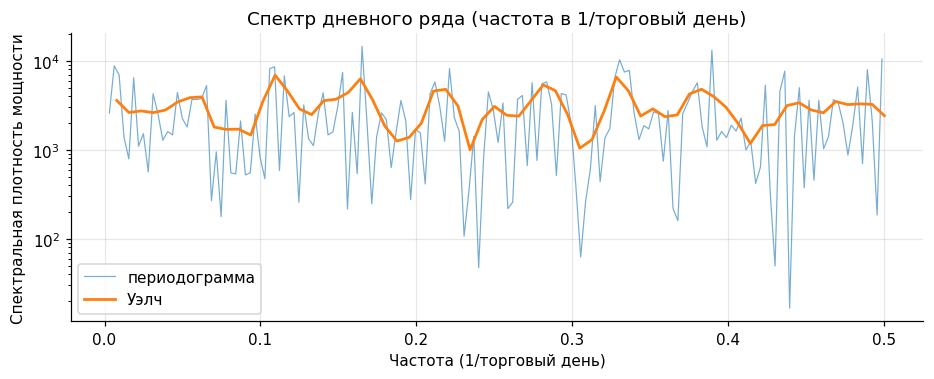

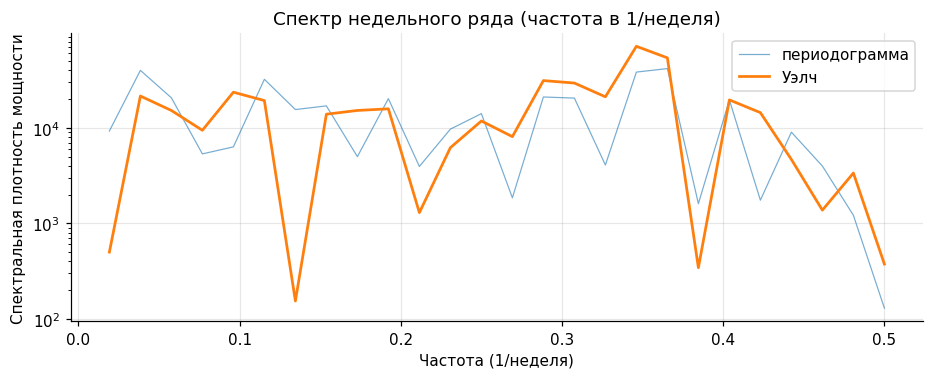

In [40]:
sp_d = T.spectral_analysis(filled, fs=1.0)
sp_w = T.spectral_analysis(weekly_filled, fs=1.0)
T.plot_spectrum(sp_d, "Спектр дневного ряда (частота в 1/торговый день)", xlabel="Частота (1/торговый день)")
T.plot_spectrum(sp_w, "Спектр недельного ряда (частота в 1/неделя)", xlabel="Частота (1/неделя)")
keys = ["dominant_period", "dominant_power_share", "centroid", "spectral_entropy", "nyquist", "freq_resolution"]
pd.DataFrame({"день": {k: sp_d[k] for k in keys}, "неделя": {k: sp_w[k] for k in keys}})

* Тест Льюнга–Бокса не выявляет значимой автокорреляции дневного ряда по совокупности лагов до 6, 12 и 24 (p = 0,76, 0,95 и 0,15). Для недельного ряда вывод совпадает при проверке до 4, 8 и 13 лагов.
* Самый высокий пик дневной периодограммы соответствует периоду 6,06 шага, почти одной неделе. На него приходится около 3,4% мощности. Высокая спектральная энтропия (0,98) показывает, что мощность распределена по многим частотам.
* Самый высокий пик недельного ряда соответствует периоду около трёх недель. При 52 наблюдениях и без подтверждения по автокорреляции этого недостаточно для вывода об устойчивом цикле. Частота Найквиста 0,5 цикла на шаг соответствует периоду в два шага.

## Шаг 4. Декомпозиция

Выбираем устойчивую STL-декомпозицию, чтобы крупный заказ меньше влиял на оценку тренда и сезонности. Период в **6 позиций дневного ряда** соответствует календарной неделе.

Сравниваем аддитивную STL на исходной шкале и STL на шкале `ln(1+y)`. Прибавление единицы позволяет брать логарифм при нулевых продажах. После обратного преобразования множители относятся к `1+y`. На каждой шкале оцениваем выраженность компоненты по тому, как меняется дисперсия после её удаления.

В данных 52 полные недели и 12 полных месяцев. Это примерно один годовой цикл, а для оценки повторяемости потребовалось бы несколько.

,сила сезонности,сила тренда
аддитивная (шт.),0.124,0.079
STL на ln(1+y),0.264,0.248


array([<Axes: title={'center': 'STL-декомпозиция дневного ряда (ln(1+y), период 6)'}, ylabel='Наблюдаемый ряд\n(ln(1+шт.))'>,
       <Axes: ylabel='Тренд\n(ln(1+шт.))'>,
       <Axes: ylabel='Сезонность\n(ln(1+шт.))'>,
       <Axes: xlabel='Дата', ylabel='Остаток\n(ln(1+шт.))'>], dtype=object)

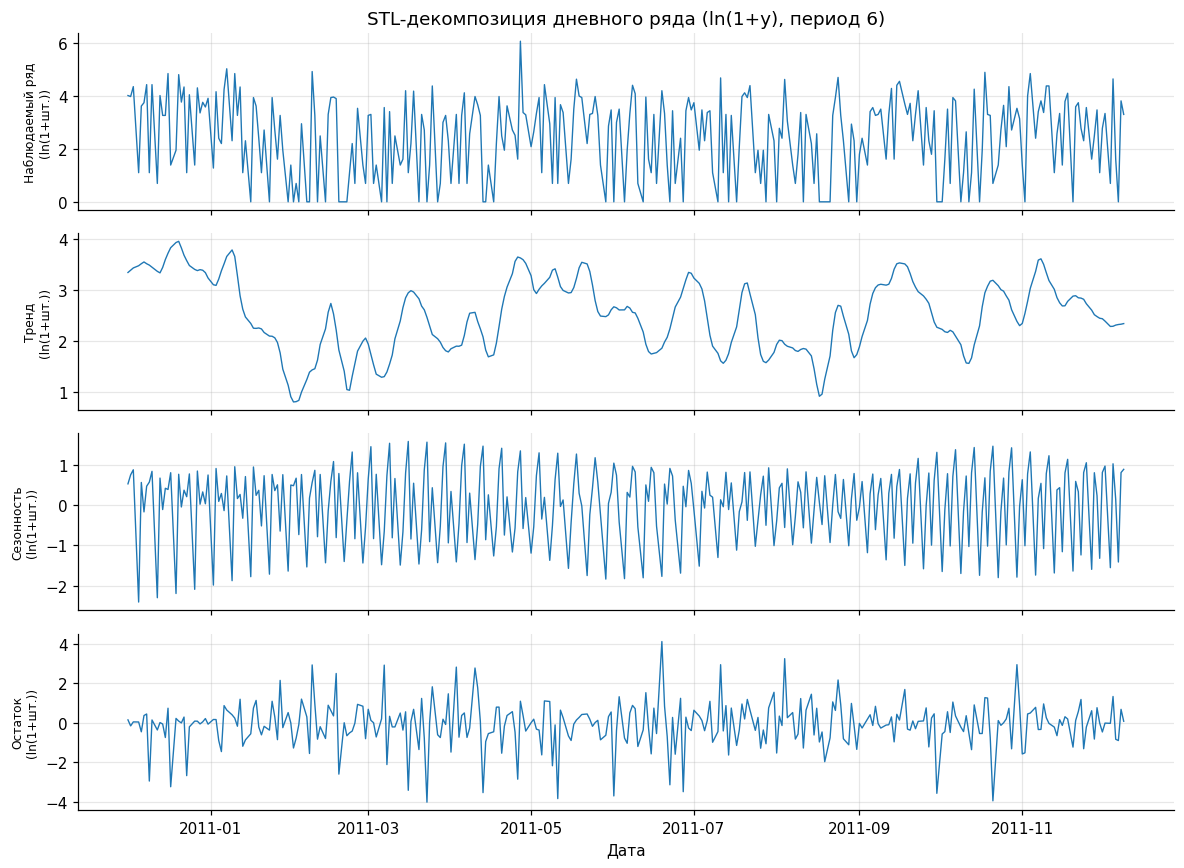

In [41]:
res_add = T.decompose(filled, period=6, method="stl", model="additive")
res_mul = T.decompose(filled, period=6, method="stl", model="multiplicative")
print("Наблюдений:", len(filled), "| для недельного ряда нужно >=", 2 * 52, "точек, есть", len(weekly),
      "| для месячного нужно >=", 2 * 12, "точек, есть", len(monthly))
display(pd.DataFrame({
    "сила сезонности": [T.seasonal_strength(res_add), T.seasonal_strength(res_mul)],
    "сила тренда": [T.trend_strength(res_add), T.trend_strength(res_mul)],
}, index=["аддитивная (шт.)", "STL на ln(1+y)"]))
T.plot_decomposition(res_mul, "STL-декомпозиция дневного ряда (ln(1+y), период 6)", ylabel="ln(1+шт.)")

In [42]:
seas = res_mul.seasonal.groupby(res_mul.seasonal.index.dayofweek).mean()
factor = np.exp(seas); factor.index = [{0:"Пн",1:"Вт",2:"Ср",3:"Чт",4:"Пт",6:"Вс"}[i] for i in factor.index]
print("Сезонные множители для 1+y по дням недели:"); display(factor.round(2).to_frame("множитель").T)
resid = res_mul.resid
print("Тест Льюнга–Бокса на остатке:"); display(T.ljung_box(resid, [6, 12, 24]))
print("СКО остатка / СКО ряда в логарифме:", round(resid.std() / np.log1p(filled).std(), 2))

,Пн,Вт,Ср,Чт,Пт,Вс
множитель,1.08,1.6,1.43,1.02,1.89,0.21


,lb_stat,lb_pvalue
6,14.414,0.025
12,31.104,0.002
24,39.199,0.026


* **Тренд.** На логарифмической шкале сила тренда составляет 0,248. Уровень меняется в отдельные периоды, устойчивого роста или спада за год не видно.
* **Сезонность.** Сила недельной компоненты равна 0,124 для ряда в штуках и 0,264 на шкале `ln(1+y)`. Сезонный множитель для `1+y` составляет около 0,21 в воскресенье и около 1,89 в пятницу.
* **Остаток.** Его СКО составляет 77% СКО логарифмированного ряда. Тест Льюнга–Бокса показывает остаточную автокорреляцию при проверке до 6, 12 и 24 лагов (p ≈ 0,025, 0,002 и 0,026).

Недельную закономерность подтверждают профиль по дням недели, тест Краскела–Уоллиса (p ≈ 7,52 × 10⁻⁸) и пик периодограммы около 6 шагов. Для проверки годовой сезонности данных недостаточно.

## Шаг 5. Стационарность

У ADF и KPSS разные нулевые гипотезы. Уровень значимости для обоих тестов равен 0,05.

* **ADF.** Нулевая гипотеза H₀ предполагает единичный корень. При малом p-значении отвергаем эту гипотезу и получаем свидетельство в пользу стационарности. Число лагов выбираем по AIC.
* **KPSS.** Нулевая гипотеза H₀ предполагает стационарность вокруг константы (`c`) или тренда (`ct`). При малом p-значении отвергаем эту гипотезу и получаем свидетельство в пользу нестационарности. Тест сравнивает статистику с табличными значениями, поэтому p-значение ограничено интервалом от 0,01 до 0,1.

По таблице из лекции результаты говорят в пользу стационарности, когда ADF отвергает свою гипотезу, а KPSS свою не отвергает. Если только KPSS отвергает свою гипотезу, результаты говорят в пользу нестационарности. Если ни один тест не отвергает свою гипотезу, результат неоднозначен. Если оба теста отвергают свои гипотезы, результаты противоречат друг другу. Возможные причины включают сдвиги в ряду или неверную спецификацию тренда.

### 5.1 Исходные ряды

In [43]:
series = {"день (заполненный)": filled, "неделя (заполненная)": weekly_filled, "месяц": monthly}
print("Модель с константой (regression='c'):"); display(T.stationarity_table(series, "c"))
print("Модель с константой и трендом (regression='ct'):"); display(T.stationarity_table(series, "ct"))

,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,verdict
name,,,,,,
день (заполненный),-18.061,2.622e-30,0,0.196,0.1,в пользу стационарности
неделя (заполненная),-4.069,1.090e-03,3,0.124,0.1,в пользу стационарности
месяц,-1.582,4.924e-01,4,0.089,0.1,неоднозначно (ни один тест не отверг H0)


,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,verdict
name,,,,,,
день (заполненный),-18.078,0.000,0,0.131,0.078,в пользу стационарности
неделя (заполненная),-4.016,0.008,3,0.102,0.100,в пользу стационарности
месяц,-4.217,0.004,2,0.088,0.100,в пользу стационарности


В тесте с константой ADF отвергает гипотезу о единичном корне для заполненных дневного (p < 0,001) и недельного (p < 0,05) рядов. KPSS не отвергает стационарность на уровне 5%. При добавлении линейного тренда оба теста дают те же решения. Для дневных продаж учитываем и найденный эффект дня недели.

У месячного ряда p-значение ADF зависит от того, включён ли тренд в регрессию (около 0,492 без тренда и 0,004 с трендом). При 12 точках данных для устойчивого вывода недостаточно.

### 5.2 Сравнение с преобразованными рядами

Сравниваем обычную и сезонную разности, логарифмирование `ln(1+y)` и ограничение верхнего 1% значений. Дневной ряд перепроверяем с линейной интерполяцией, недельный с нулём записанных продаж в пропущенную неделю.

In [44]:
variants = {
    "день: заполненный": filled,
    "день: линейная интерполяция": linear,
    "день: разность лаг 1": T.difference(filled, 1),
    "день: сезонная разность лаг 6": T.difference(filled, 6),
    "день: ln(1+y)": np.log1p(filled),
    "день: winsorize 99%": T.winsorize(filled),
    "неделя: линейная интерполяция": weekly_filled,
    "неделя: 0 записанных продаж в пропущенную неделю": weekly.fillna(0),
    "неделя: разность лаг 1": T.difference(weekly_filled, 1),
    "неделя: ln(1+y)": np.log1p(weekly_filled),
    "неделя: winsorize 99%": T.winsorize(weekly_filled),
}
tab = T.stationarity_table(variants, "c")
tab["ACF(1)"] = [acf(s.dropna(), nlags=1)[1] for s in variants.values()]
display(tab)
print("ln(1+y) дневной ряд, число лагов ADF по BIC вместо AIC:")
display(T.stationarity_table({"день: ln(1+y), BIC": np.log1p(filled)}, "c", autolag="BIC"))

,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,verdict,ACF(1)
name,,,,,,,
день: заполненный,-18.061,2.622e-30,0,0.196,0.1,в пользу стационарности,-1.180e-02
день: линейная интерполяция,-17.650,3.724e-30,0,0.082,0.1,в пользу стационарности,1.127e-02
день: разность лаг 1,-8.216,6.612e-13,17,0.156,0.1,в пользу стационарности,-5.162e-01
день: сезонная разность лаг 6,-9.789,6.431e-17,11,0.016,0.1,в пользу стационарности,1.429e-03
день: ln(1+y),-2.822,5.524e-02,17,0.159,0.1,неоднозначно (ни один тест не отверг H0),2.181e-02
день: winsorize 99%,-17.844,3.099e-30,0,0.268,0.1,в пользу стационарности,9.063e-04
неделя: линейная интерполяция,-4.069,1.090e-03,3,0.124,0.1,в пользу стационарности,1.166e-01
неделя: 0 записанных продаж в пропущенную неделю,-3.786,3.051e-03,3,0.068,0.1,в пользу стационарности,-9.436e-03
неделя: разность лаг 1,-4.238,5.685e-04,5,0.140,0.1,в пользу стационарности,-4.151e-01


,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,verdict
name,,,,,,
"день: ln(1+y), BIC",-17.469,4.555e-30,0,0.159,0.1,в пользу стационарности


array([<Axes: title={'center': 'ACF: дневной ряд после разности лаг 1'}, xlabel='Лаг', ylabel='Автокорреляция'>,
       <Axes: title={'center': 'PACF: дневной ряд после разности лаг 1'}, xlabel='Лаг', ylabel='Частичная автокорреляция'>],
      dtype=object)

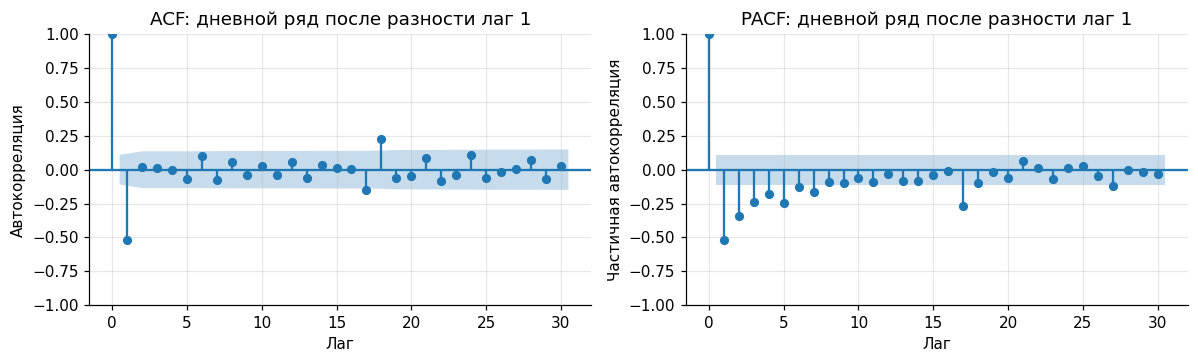

In [45]:
T.plot_acf_pacf(T.difference(filled, 1), 30, "дневной ряд после разности лаг 1")

* После первой разности ACF(1) меняется с −0,012 до −0,516 в дневном ряду. В недельном ряду тоже появляется заметная отрицательная автокорреляция. Исходные результаты ADF и KPSS не дают оснований брать разность.
* Выводы ADF и KPSS для недельного ряда совпадают при линейной интерполяции и при подстановке нуля записанных продаж.
* При ограничении верхнего 1% значений оба теста дают те же решения. Поэтому наблюдение от 27 апреля оставляем в ряду.
* После `ln(1+y)` решение ADF для дневных продаж зависит от выбора числа лагов (p ≈ 0,055 при AIC, p < 0,001 при BIC). Логарифм использовали для сравнения вариантов STL.
* Пропуски заполняем для анализа. В прогнозе календарный эффект можно учесть признаком дня недели. Оценки по соседним датам нужно вычислять внутри обучающей выборки.

## Шаг 6. Проверка на другом товаре

Сверяем сводку по товару `84692` с расчётами выше и запускаем те же функции для товара `22467`.

In [46]:
summary = T.run_pipeline(df, CODE)
assert T.make_daily(df, CODE).equals(daily)
assert summary["стационарность (день)"] == T.stationarity_tests(filled, "d").verdict
assert summary["стационарность (неделя)"] == T.stationarity_tests(weekly_filled, "w").verdict
assert summary["сила сезонности STL (log1p)"] == round(T.seasonal_strength(res_mul), 3)

summaries = pd.DataFrame({code: T.run_pipeline(df, code) for code in [CODE, "22467"]})
p_row = "p Краскела-Уоллиса по дням недели"
summaries.loc[p_row] = summaries.loc[p_row].map("{:.2e}".format)
summaries

,84692,22467
code,84692,22467
описание,BOX OF 24 COCKTAIL PARASOLS,GUMBALL COAT RACK
дней в ряду / без транзакций (NaN),321 / 16,321 / 16
доля нулевых торговых дней,0.151,0.151
выбросов IQR (день),14,18
CV (день),1.44,1.45
p Краскела-Уоллиса по дням недели,7.52e-08,2.61e-03
сила сезонности STL (log1p),0.264,0.112
стационарность (день),в пользу стационарности,в пользу стационарности
стационарность (неделя),в пользу стационарности,в пользу стационарности


## Шаг 7. Выводы

* Для товара `84692` построили ряды на 321 дневную позицию, 52 полные календарные недели и 12 полных месяцев. Объём наблюдаемых продаж за весь период составил 7 908 шт.
* В дневном ряду 16 дат без транзакций по магазину и 46 наблюдаемых дней с нулём продаж товара. Для части расчётов заполнили пропуски по соседним значениям того же дня недели.
* IQR отметил 14 дней. Максимум (426 шт. 27 апреля 2011 года) объясняется заказом на 400 шт. и сохранён в ряду.
* Недельная агрегация сглаживает колебания (CV падает с 1,44 до 0,57). Линейный тренд за период не обнаружен. По воскресеньям продавалось в среднем 6,8 шт. против 26–34 шт. по будням. Данных для оценки годовой сезонности недостаточно.
* На уровне 5% тесты ADF и KPSS дают согласованные результаты в пользу стационарности заполненных дневного и недельного рядов. Вывод по месячному ряду неустойчив. Для итоговой предобработки обошлись без дифференцирования. Недельная частота подходит для прогноза суммарных продаж за неделю. В дневном прогнозе нужно учесть эффект дня недели.